In [1]:
from google.colab import files
uploaded = files.upload()   # click "Choose Files" and select medical-wsd.zip

Saving medical-wsd.zip to medical-wsd.zip


In [2]:
import zipfile, os
with zipfile.ZipFile('medical-wsd.zip', 'r') as z:
    z.extractall('.')
os.chdir('medical-wsd')
print("Now in:", os.getcwd())

Now in: /content/medical-wsd


In [3]:
!pip install -q pennylane

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 83.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 58.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 31.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 82.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 102.4 MB/s eta 0:00:00


In [4]:
import sys, json
sys.path.insert(0, '.')

def load_jsonl(path):
    return [json.loads(l) for l in open(path)]

records = load_jsonl('data/processed/real_wsd_preprocessed.jsonl')
train = [r for r in records if r['split'] == 'train']
test  = [r for r in records if r['split'] == 'test']
print(f"{len(train)} train / {len(test)} test real examples")

from collections import Counter
print("Abbreviations:", Counter(r['abbreviation'] for r in records))

404 train / 91 test real examples
Abbreviations: Counter({'LAD': 203, 'AP': 107, 'MS': 89, 'AV': 77, 'PDA': 33, 'PA': 24, 'PE': 24, 'CA': 23})


In [5]:
from src.models.majority_baseline import MajorityBaseline
from src.evaluation.metrics import compute_core_metrics

m1 = MajorityBaseline().fit(train)
preds1, confs1, _ = m1.predict(test)
labels = [r['label'] for r in test]
metrics1 = compute_core_metrics(labels, preds1)
print("Majority:", {k: metrics1[k] for k in ['accuracy', 'macro_f1', 'weighted_f1']})

Majority: {'accuracy': 0.9560439560439561, 'macro_f1': 0.9551282051282051, 'weighted_f1': 0.9557621865314173}


In [6]:
from src.models.tfidf_logreg import TfidfLogRegWSD

m2 = TfidfLogRegWSD(context_field='context_2').fit(train)
preds2, confs2, _ = m2.predict(test)
metrics2 = compute_core_metrics(labels, preds2)
print("TF-IDF+LogReg:", {k: metrics2[k] for k in ['accuracy', 'macro_f1', 'weighted_f1']})

TF-IDF+LogReg: {'accuracy': 1.0, 'macro_f1': 1.0, 'weighted_f1': 1.0}


In [7]:
from src.models.quantum_classifier import QuantumVariationalWSD

m3 = QuantumVariationalWSD(context_field='context_2', n_qubits=6, n_layers=3, epochs=60, lr=0.15)
m3.fit(train, verbose=True)
preds3, confs3, _ = m3.predict(test)
metrics3 = compute_core_metrics(labels, preds3)
print("Quantum:", {k: metrics3[k] for k in ['accuracy', 'macro_f1', 'weighted_f1']})

  [quantum:AV] epoch 12/60 loss=0.1847
  [quantum:AV] epoch 24/60 loss=0.0569
  [quantum:AV] epoch 36/60 loss=0.0256
  [quantum:AV] epoch 48/60 loss=0.0131
  [quantum:AV] epoch 60/60 loss=0.0095
  [quantum:AP] epoch 12/60 loss=0.0771
  [quantum:AP] epoch 24/60 loss=0.0411
  [quantum:AP] epoch 36/60 loss=0.0169
  [quantum:AP] epoch 48/60 loss=0.0064
  [quantum:AP] epoch 60/60 loss=0.0034
  [quantum:PE] epoch 12/60 loss=0.2688
  [quantum:PE] epoch 24/60 loss=0.1161
  [quantum:PE] epoch 36/60 loss=0.0593
  [quantum:PE] epoch 48/60 loss=0.0344
  [quantum:PE] epoch 60/60 loss=0.0203
  [quantum:PA] epoch 12/60 loss=0.0704
  [quantum:PA] epoch 24/60 loss=0.0071
  [quantum:PA] epoch 36/60 loss=0.0015
  [quantum:PA] epoch 48/60 loss=0.0005
  [quantum:PA] epoch 60/60 loss=0.0003
  [quantum:PDA] epoch 12/60 loss=0.0994
  [quantum:PDA] epoch 24/60 loss=0.0259
  [quantum:PDA] epoch 36/60 loss=0.0095
  [quantum:PDA] epoch 48/60 loss=0.0040
  [quantum:PDA] epoch 60/60 loss=0.0023
Quantum: {'accuracy'

In [8]:
import numpy as np
from src.evaluation.metrics import per_abbreviation_performance

def corrected_summary(name, preds):
    per_abbr = per_abbreviation_performance(test, preds)
    accs = [m['accuracy'] for m in per_abbr.values()]
    f1s = [m['macro_f1'] for m in per_abbr.values()]
    ns = [m['n'] for m in per_abbr.values()]
    overall_acc = sum(p == l for p, l in zip(preds, labels)) / len(labels)
    print(f"{name:16s} overall_acc={overall_acc:.3f}  "
          f"weighted_macro_f1={np.average(f1s, weights=ns):.3f}")
    return per_abbr

pa1 = corrected_summary('Majority', preds1)
pa2 = corrected_summary('TF-IDF+LogReg', preds2)
pa3 = corrected_summary('Quantum', preds3)

print(f"\n{'abbr':6s}{'n':>4s}{'Majority':>10s}{'TFIDF':>10s}{'Quantum':>10s}")
for abbr in pa1:
    print(f"{abbr:6s}{pa1[abbr]['n']:4d}{pa1[abbr]['macro_f1']:10.3f}"
          f"{pa2[abbr]['macro_f1']:10.3f}{pa3[abbr]['macro_f1']:10.3f}")

Majority         overall_acc=0.956  weighted_macro_f1=0.936
TF-IDF+LogReg    overall_acc=1.000  weighted_macro_f1=1.000
Quantum          overall_acc=1.000  weighted_macro_f1=1.000

abbr     n  Majority     TFIDF   Quantum
LAD     41     1.000     1.000     1.000
CA       4     1.000     1.000     1.000
AP      14     1.000     1.000     1.000
PDA      4     1.000     1.000     1.000
AV       9     0.357     1.000     1.000
MS      13     1.000     1.000     1.000
PE       3     1.000     1.000     1.000
PA       3     1.000     1.000     1.000


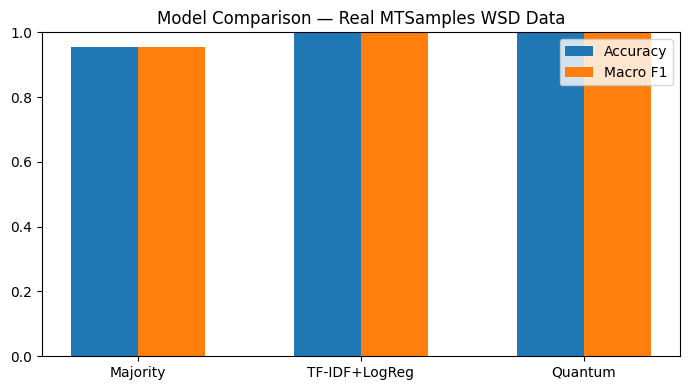

In [9]:
import matplotlib.pyplot as plt

models = ['Majority', 'TF-IDF+LogReg', 'Quantum']
accs = [metrics1['accuracy'], metrics2['accuracy'], metrics3['accuracy']]
f1s  = [metrics1['macro_f1'], metrics2['macro_f1'], metrics3['macro_f1']]

x = range(len(models))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([i - 0.15 for i in x], accs, width=0.3, label='Accuracy')
ax.bar([i + 0.15 for i in x], f1s, width=0.3, label='Macro F1')
ax.set_xticks(list(x)); ax.set_xticklabels(models)
ax.set_ylim(0, 1); ax.legend()
plt.title('Model Comparison — Real MTSamples WSD Data')
plt.tight_layout()
plt.show()